<sub>**The Annotated ML Handbook** · Part VII: ML for Research</sub>

# Chapter 30: Choosing models and metrics, and comparing them rigorously

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mahir-606/annotated-ml-handbook/blob/main/notebooks/part-7-ml-for-research/30-research-choosing.ipynb)

Companion code for the chapter. Every example from the book is here, in order, ready to run. The line-by-line explanations, definitions and discussion are in the book.

Run the setup cell first, then run the cells from top to bottom.

In [1]:
# Repository setup (not part of the book's examples): run this cell first.
import os, sys
from pathlib import Path

# Files the examples create (CSV, models, figures) go into ./outputs next to the notebook.
OUT = Path.cwd() if Path.cwd().name == "outputs" else Path.cwd() / "outputs"
OUT.mkdir(exist_ok=True)
os.chdir(OUT)

# insurance.csv is the practice dataset created in Chapter 11 and reused by later chapters.
# If it is not here yet, copy it from the repository's data/ folder (or download it in Colab).
if not Path("insurance.csv").exists():
    import shutil, urllib.request
    for base in OUT.parents:
        if (base / "data" / "insurance.csv").exists():
            shutil.copy(base / "data" / "insurance.csv", "insurance.csv")
            break
    else:
        try:
            urllib.request.urlretrieve("https://raw.githubusercontent.com/Mahir-606/"
                                       "annotated-ml-handbook/main/data/insurance.csv", "insurance.csv")
        except Exception as e:
            print("Could not fetch insurance.csv; run Chapter 11 first.", e)

# The figure style used in the book.
import matplotlib.pyplot as plt
from cycler import cycler
plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.28, "grid.linewidth": 0.6,
    "axes.prop_cycle": cycler(color=["#1f4fff", "#e0245e", "#0f9b62", "#ff6a00",
                                     "#7b3ff2", "#0091b3", "#d99a00", "#d42a2a"]),
    "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.titlelocation": "left",
    "font.size": 10.5, "legend.frameon": False, "image.cmap": "viridis",
})

# Plotly: interactive in Jupyter/Colab; tools/run_all.py stores static PNGs so GitHub can show them.
try:
    import plotly.io as pio
    pio.renderers.default = os.environ.get("PLOTLY_RENDERER") or (
        "colab" if "google.colab" in sys.modules else "notebook_connected")
except ImportError:
    pass

## 30.1 A model-selection map · *Beginner*

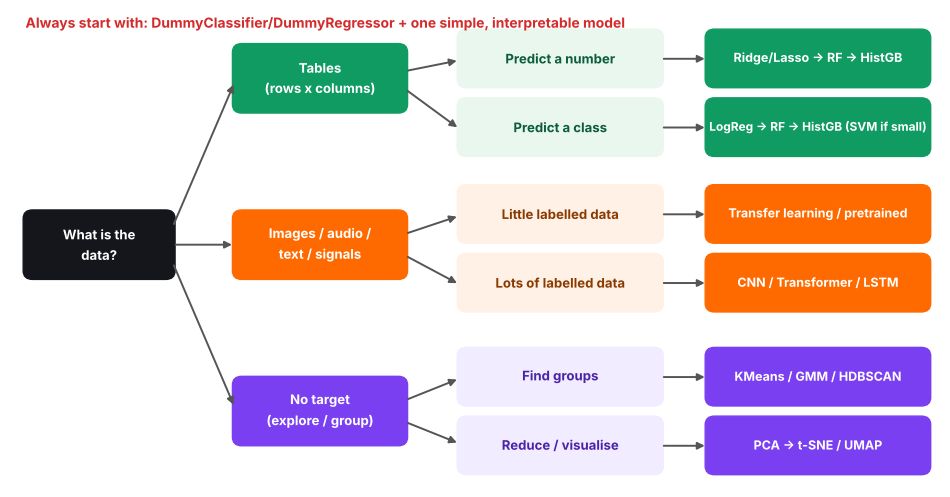

In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(12, 6.2)); ax.set_xlim(0, 12); ax.set_ylim(0, 6.6); ax.axis("off")
def box(x, y, w, h, text, color, tc="white", fs=9.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.03,rounding_size=0.12", color=color))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", color=tc, fontsize=fs, fontweight="bold", linespacing=1.3)
def arrow(x1, y1, x2, y2, label=""):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="-|>", color="#555", lw=1.4))
    if label: ax.text((x1 + x2) / 2 + 0.05, (y1 + y2) / 2 + 0.08, label, fontsize=8.5, color="#333")
box(0.2, 2.9, 1.9, 0.9, "What is the\ndata?", "#14161c")
box(2.9, 5.2, 2.2, 0.9, "Tables\n(rows x columns)", "#0f9b62")
box(2.9, 2.9, 2.2, 0.9, "Images / audio /\ntext / signals", "#ff6a00")
box(2.9, 0.6, 2.2, 0.9, "No target\n(explore / group)", "#7b3ff2")
arrow(2.1, 3.6, 2.9, 5.6); arrow(2.1, 3.35, 2.9, 3.35); arrow(2.1, 3.1, 2.9, 1.1)
box(5.8, 5.55, 2.6, 0.75, "Predict a number", "#e9f7ef", "#0b5d3b"); box(5.8, 4.6, 2.6, 0.75, "Predict a class", "#e9f7ef", "#0b5d3b")
arrow(5.1, 5.75, 5.8, 5.9); arrow(5.1, 5.5, 5.8, 4.95)
box(9.0, 5.55, 2.85, 0.75, "Ridge/Lasso -> RF -> HistGB", "#0f9b62", fs=9)
box(9.0, 4.6, 2.85, 0.75, "LogReg -> RF -> HistGB (SVM if small)", "#0f9b62", fs=8.6)
arrow(8.4, 5.92, 9.0, 5.92); arrow(8.4, 4.97, 9.0, 4.97)
box(5.8, 3.4, 2.6, 0.75, "Little labelled data", "#fff1e6", "#8a3a00"); box(5.8, 2.45, 2.6, 0.75, "Lots of labelled data", "#fff1e6", "#8a3a00")
arrow(5.1, 3.5, 5.8, 3.75); arrow(5.1, 3.2, 5.8, 2.8)
box(9.0, 3.4, 2.85, 0.75, "Transfer learning / pretrained", "#ff6a00", fs=9); box(9.0, 2.45, 2.85, 0.75, "CNN / Transformer / LSTM", "#ff6a00", fs=9)
arrow(8.4, 3.77, 9.0, 3.77); arrow(8.4, 2.82, 9.0, 2.82)
box(5.8, 1.15, 2.6, 0.75, "Find groups", "#f1ecff", "#4b23a8"); box(5.8, 0.2, 2.6, 0.75, "Reduce / visualise", "#f1ecff", "#4b23a8")
arrow(5.1, 1.2, 5.8, 1.5); arrow(5.1, 0.9, 5.8, 0.6)
box(9.0, 1.15, 2.85, 0.75, "KMeans / GMM / HDBSCAN", "#7b3ff2", fs=9); box(9.0, 0.2, 2.85, 0.75, "PCA -> t-SNE / UMAP", "#7b3ff2", fs=9)
arrow(8.4, 1.52, 9.0, 1.52); arrow(8.4, 0.57, 9.0, 0.57)
ax.text(0.2, 6.35, "Always start with: DummyClassifier/DummyRegressor + one simple, interpretable model", fontsize=10, color="#d42a2a", fontweight="bold")
plt.show()

### 30.1.1 Rules of thumb · *Beginner*

## 30.2 Choosing the metric · *Beginner*

## 30.3 Is model A really better than model B? · *Intermediate*

### 30.3.1 1. Corrected resampled t-test on CV scores · *Advanced*

**Comparing two models on identical repeated-CV splits**

In [3]:
import numpy as np
from scipy import stats
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

X, y = load_breast_cancer(return_X_y=True)
cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=10, random_state=0)
a = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)), X, y, cv=cv, scoring="roc_auc", n_jobs=-1)
b = cross_val_score(RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1), X, y, cv=cv, scoring="roc_auc", n_jobs=-1)

def corrected_ttest(a, b, n_train, n_test):
    d = a - b
    k = len(d)
    var = d.var(ddof=1) * (1 / k + n_test / n_train)
    t = d.mean() / np.sqrt(var)
    p = 2 * stats.t.sf(abs(t), df=k - 1)
    return d.mean(), t, p

n = len(y)
diff, t, p = corrected_ttest(a, b, n_train=int(n * 0.9), n_test=n - int(n * 0.9))
naive_p = stats.ttest_rel(a, b).pvalue
print(f"mean AUC: LogReg={a.mean():.4f}  RF={b.mean():.4f}  difference={diff:+.4f}")
print(f"corrected t={t:.2f}, p={p:.4f}   |   naive paired t-test p={naive_p:.2e} (overconfident)")

mean AUC: LogReg=0.9949  RF=0.9905  difference=+0.0044
corrected t=1.08, p=0.2849   |   naive paired t-test p=3.03e-04 (overconfident)


### 30.3.2 2. McNemar's test on a single test set · *Intermediate*

**Exact McNemar test**

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=1)
pa = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(X_tr, y_tr).predict(X_te)
pb = make_pipeline(StandardScaler(), SVC()).fit(X_tr, y_tr).predict(X_te)
a_right_b_wrong = int(((pa == y_te) & (pb != y_te)).sum())
a_wrong_b_right = int(((pa != y_te) & (pb == y_te)).sum())
res = stats.binomtest(a_right_b_wrong, a_right_b_wrong + a_wrong_b_right, p=0.5)
print(f"LogReg acc={np.mean(pa == y_te):.3f}  SVC acc={np.mean(pb == y_te):.3f}")
print(f"discordant: LogReg-only correct={a_right_b_wrong}, SVC-only correct={a_wrong_b_right}, exact McNemar p={res.pvalue:.3f}")

LogReg acc=0.959  SVC acc=0.977
discordant: LogReg-only correct=1, SVC-only correct=4, exact McNemar p=0.375


### 30.3.3 3. Paired bootstrap for any metric · *Intermediate*

**95% CI for the difference in test AUC**

In [5]:
from sklearn.metrics import roc_auc_score
prob_a = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(X_tr, y_tr).predict_proba(X_te)[:, 1]
prob_b = RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1).fit(X_tr, y_tr).predict_proba(X_te)[:, 1]
rng = np.random.default_rng(0)
diffs = []
for _ in range(3000):
    idx = rng.integers(0, len(y_te), len(y_te))
    if y_te[idx].min() == y_te[idx].max():
        continue
    diffs.append(roc_auc_score(y_te[idx], prob_a[idx]) - roc_auc_score(y_te[idx], prob_b[idx]))
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"AUC difference (LogReg - RF) = {roc_auc_score(y_te, prob_a) - roc_auc_score(y_te, prob_b):+.4f}, 95% CI [{lo:+.4f}, {hi:+.4f}]")
print("CI includes 0 -> no evidence of a difference" if lo < 0 < hi else "CI excludes 0 -> evidence of a difference")

AUC difference (LogReg - RF) = +0.0062, 95% CI [-0.0069, +0.0232]
CI includes 0 -> no evidence of a difference


## 30.4 How much data do I need? · *Intermediate*

**Precision of an accuracy estimate vs test-set size**

In [6]:
for n_test in [50, 100, 200, 500, 1000, 5000]:
    p_hat = 0.85
    half_width = 1.96 * np.sqrt(p_hat * (1 - p_hat) / n_test)
    print(f"n_test={n_test:>5}: accuracy 0.85 ± {half_width:.3f}")

n_test=   50: accuracy 0.85 ± 0.099
n_test=  100: accuracy 0.85 ± 0.070
n_test=  200: accuracy 0.85 ± 0.049
n_test=  500: accuracy 0.85 ± 0.031
n_test= 1000: accuracy 0.85 ± 0.022
n_test= 5000: accuracy 0.85 ± 0.010


## Try it yourself

1. Use the corrected t-test to compare `SVC` and `LogisticRegression` on the wine dataset.
2. Run the paired bootstrap with `average_precision_score` instead of ROC AUC.
3. Simulate: draw two models with identical true accuracy and count how often the naive t-test on CV scores declares p < 0.05.

Worked solutions: [solutions-parts-5-8.ipynb](../../solutions/solutions-parts-5-8.ipynb), section *Chapter 30*.